# STATS 425 Fall 2026 · Week 3 discussion
**How language models generate text**  
**TA:** Ali Kaazempur-Mofrad

In Week 1, we examined next-token probabilities and used them to calculate loss and perplexity. In Week 2, we used loss to update the model's weights. Today, we keep the weights fixed and study how the model turns its predictions into text.

| Section | Question we answer |
|---|---|
| 1. Generating text one token at a time | How does one prediction become a sequence? |
| 2. Greedy decoding | What happens when we always choose the most likely next token? |
| 3. Sampling and temperature | How can we choose different continuations from the same predictions? |
| 4. Comparing generated text | How do these choices affect the output? |
| 5. Top-k and top-p sampling | How can we limit which tokens are eligible for sampling? |


**Set up the notebook.** We use the same Transformers version as the previous discussions.

The setup cell also checks the PyTorch version. If it installs or updates any packages, **restart the notebook kernel/runtime, then run the cells again from the top**. Restarting lets Python load the updated libraries.

In [1]:
import importlib.metadata
import subprocess
import sys


def installed_version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return None


required = {"transformers": "4.57.6", "huggingface-hub": "0.36.2", "tokenizers": "0.22.2"}
packages = [f"{name}=={version}" for name, version in required.items()
            if installed_version(name) != version]

# Matplotlib draws the temperature plot in Section 3.
matplotlib_version = installed_version("matplotlib")
if matplotlib_version is None or tuple(map(int, matplotlib_version.split(".")[:2])) < (3, 9):
    packages.append("matplotlib>=3.9,<4")

# Keep a recent PyTorch installation, or upgrade to the version tested here.
torch_version = installed_version("torch")
if torch_version is None or tuple(map(int, torch_version.split(".")[:2])) < (2, 8):
    packages.append("torch==2.8.0")
    # If present, keep these companion packages compatible with PyTorch.
    # Version pairs: https://pytorch.org/get-started/previous-versions/#v280
    for name, version in {"torchvision": "0.23.0", "torchaudio": "2.8.0"}.items():
        if installed_version(name) is not None:
            packages.append(f"{name}=={version}")

if packages:
    print("Installing:", ", ".join(packages))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *packages])
    print("Installation complete. Restart the kernel/runtime, then run the cells again from the top.")
else:
    print("Setup complete.")

Setup complete.


## 1 · Generating text one token at a time

In Week 1, we gave the model a sentence and measured its probability for each observed next token. **During generation, we choose the next token ourselves from the model's predictions.** We append that token to the input, ask for a new prediction, and repeat. This is called **autoregressive generation**.

Consider a possible continuation:

| Step | Text the model receives | Token chosen at this step |
|---|---|---|
| 1 | `The old library was quiet. Emma opened a dusty book and found` | `' a'` |
| 2 | `The old library was quiet. Emma opened a dusty book and found a` | `' letter'` |
| 3 | `The old library was quiet. Emma opened a dusty book and found a letter` | `'.'` |

This table illustrates the process; the actual model may choose different tokens. 

**Load the model.** We load the same pretrained DistilGPT2 checkpoint used at the start of Weeks 1 and 2. This notebook runs independently and does not require the weights fine-tuned in Week 2.

`model.eval()` turns off dropout. `torch.no_grad()` tells PyTorch that we do not need gradients for these predictions. Neither operation updates the weights.

In [2]:
import os
import torch
import transformers
from transformers import AutoTokenizer, AutoModelForCausalLM, set_seed

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cpu":
    torch.set_num_threads(min(4, os.cpu_count() or 1))

MODEL_ID = "distilbert/distilgpt2"
REVISION = "2290a62682d06624634c1f46a6ad5be0f47f38aa"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, revision=REVISION, use_safetensors=True
).to(device)
tokenizer.pad_token = tokenizer.eos_token
model.eval()

PROMPT = "The old library was quiet. Emma opened a dusty book and found"
inputs = tokenizer(PROMPT, return_tensors="pt").to(device)
print("Prompt:", PROMPT)
print("Prompt length:", inputs.input_ids.shape[1], "tokens")

Prompt: The old library was quiet. Emma opened a dusty book and found
Prompt length: 13 tokens


**From logits to probabilities.** For a given context, the model produces one score, called a **logit**, for every possible next token. A logit can be any real number, including a negative number.

**Calculating a logit.** At the model's output layer, the score for token $i$ is

$$z_i=w_i^\toph=\sum_{k=1}^{d}w_{ik}h_k$$

Here, $h$ is the model's numerical representation of the current context, and $w_i$ contains learned weights associated with token $i$. Both vectors have $d$ entries. Multiplying corresponding entries and adding them gives the logit $z_i$.

The model uses the same context vector $h$ to calculate a score for every token, using each token's corresponding weights.

Let $V$ be the number of tokens in the vocabulary. **Softmax** converts all $V$ logits into next-token probabilities:

$$p_i=P(\text{next token}=i\mid\text{context})=\frac{e^{z_i}}{\sum_{j=1}^{V}e^{z_j}}$$

Exponentiating makes each value positive. Dividing by the sum makes the probabilities add to one:

$$\sum_{i=1}^{V}p_i=\frac{\sum_{i=1}^{V}e^{z_i}}{\sum_{j=1}^{V}e^{z_j}}=1$$

A larger logit gives a larger probability. Softmax preserves the ordering of the scores.

**Example:** For this example, suppose the vocabulary contains only four tokens with the following logits.

| Token | Logit $z_i$ | Exponentiated score $e^{z_i}$ | Probability $p_i$ |
|---|---:|---:|---:|
| `' dragon'` | $\ln 12\approx2.485$ | 12 | $12/20=0.60$ |
| `' fox'` | $\ln 5\approx1.609$ | 5 | $5/20=0.25$ |
| `' castle'` | $\ln 2\approx0.693$ | 2 | $2/20=0.10$ |
| `' spaceship'` | $\ln 1=0$ | 1 | $1/20=0.05$ |

The denominator is $12+5+2+1=20$. For example, the probability of `' dragon'` is

$$p_{\text{dragon}}=\frac{e^{\ln 12}}{e^{\ln 12}+e^{\ln 5}+e^{\ln 2}+e^0}=\frac{12}{20}=0.60$$


**Follow four generation steps.** In the code below, `logits[0, -1]` selects the scores after the last token of our one input sequence. `torch.softmax(logits, dim=-1)` applies the formula above across the full vocabulary. `dim=-1` specifies the token dimension over which the probabilities must add to one.

For now, we choose the highest-probability token at each step. After choosing it, `torch.cat` appends its ID to the current input. The next pass through the loop uses this longer input.

Each step prints the current context, the five most likely next tokens, and the selected token. Quotes make leading spaces visible: `' a'` includes the space that separates it from the preceding word.

In [3]:
MANUAL_STEPS = 4
manual_ids = inputs.input_ids.clone()
manual_trace = []

with torch.no_grad():
    for step in range(1, MANUAL_STEPS + 1):
        logits = model(input_ids=manual_ids).logits[0, -1]
        probabilities = torch.softmax(logits, dim=-1)
        top_probs, top_ids = torch.topk(probabilities, k=5)
        next_id = int(probabilities.argmax())

        print(f"Step {step} | Context: {tokenizer.decode(manual_ids[0])}")
        for token_id, probability in zip(top_ids.tolist(), top_probs.tolist()):
            print(f"  {tokenizer.decode([token_id])!r:<20} {probability:.4f}")
        print("Chosen token:", repr(tokenizer.decode([next_id])))
        print()

        manual_trace.append({"token_id": next_id, "probability": float(probabilities[next_id])})
        next_token = torch.tensor([[next_id]], device=device)
        manual_ids = torch.cat([manual_ids, next_token], dim=1)
        if next_id == tokenizer.eos_token_id:
            break

print("Text after these steps:", tokenizer.decode(manual_ids[0], skip_special_tokens=True))

Step 1 | Context: The old library was quiet. Emma opened a dusty book and found
  ' a'                 0.2540
  ' the'               0.1492
  ' it'                0.1224
  ' that'              0.0514
  ' her'               0.0456
Chosen token: ' a'

Step 2 | Context: The old library was quiet. Emma opened a dusty book and found a
  ' book'              0.0771
  ' few'               0.0465
  ' small'             0.0211
  ' copy'              0.0210
  ' new'               0.0190
Chosen token: ' book'

Step 3 | Context: The old library was quiet. Emma opened a dusty book and found a book
  '.'                  0.1640
  ' on'                0.1071
  ' of'                0.0744
  ','                  0.0656
  ' about'             0.0646
Chosen token: '.'

Step 4 | Context: The old library was quiet. Emma opened a dusty book and found a book.
  ' She'               0.2249
  '\n'                 0.1787
  ' Emma'              0.0623
  ' The'               0.0594
  ' "'                 0.0546
C

Each new context contains the token selected in the previous step. Its probabilities can therefore differ from the previous step even though the model's weights have not changed.

The chosen token always appears first in the candidate list because we selected the largest probability. This selection rule is called greedy decoding.

## 2 · Greedy decoding

**Greedy decoding** chooses the most likely token at each step. That is exactly the rule in Section 1. In Hugging Face, `do_sample=False` with `num_beams=1` selects greedy decoding.

The next cell asks `generate()` for the same number of new tokens as our manual loop and prints the two continuations together. Both start with the original prompt.

`max_new_tokens` is a limit on the number of **additional tokens**, not words. Generation can stop earlier if the model produces an end-of-sequence token, **EOS**. We use EOS as the padding ID because this tokenizer has no separate padding token; our examples contain one unpadded prompt at a time.

For this decoder-only model, `generate()` returns the prompt IDs followed by the generated IDs. We slice off the prompt so the printed continuation shows only the newly generated text.

In [4]:
with torch.no_grad():
    greedy_ids = model.generate(
        **inputs,
        max_new_tokens=MANUAL_STEPS,
        do_sample=False,
        num_beams=1,
        pad_token_id=tokenizer.pad_token_id,
        eos_token_id=tokenizer.eos_token_id,
    )

prompt_length = inputs.input_ids.shape[1]
print("Original prompt:", PROMPT)
print("Manual loop:    ", repr(tokenizer.decode(manual_ids[0, prompt_length:], skip_special_tokens=True)))
print("generate():     ", repr(tokenizer.decode(greedy_ids[0, prompt_length:], skip_special_tokens=True)))

Original prompt: The old library was quiet. Emma opened a dusty book and found
Manual loop:     ' a book. She'
generate():      ' a book. She'


The continuations should match: both methods repeatedly apply the same choice to the same predictions. With the same input and model settings, greedy decoding has no random token selection.

**Does choosing the most likely token always give the most likely whole continuation?** No. Consider two possible paths in an invented two-step example:

| Path | Probability of first token | Probability of second token, given the first | Probability of the two-token path |
|---|---:|---:|---:|
| A → X | 0.60 | 0.40 | 0.60 × 0.40 = 0.24 |
| B → Y | 0.40 | 0.90 | 0.40 × 0.90 = 0.36 |

Suppose X is the most likely token after A and Y is the most likely after B. Greedy decoding starts with A, so it cannot reach B → Y, even though that path has a higher probability. It makes the best immediate choice without looking ahead. Also, a high-probability continuation is not necessarily an accurate or useful answer.

We will now try a different rule: allow the model to choose among several possible tokens, with more probable tokens more likely to be selected.

## 3 · Sampling and temperature

**Sampling** draws a token according to a probability distribution. A token with probability 0.60 is selected about 60% of the time over many draws from that same distribution; it is not selected on every draw. Different choices can send generation down different paths.

**Temperature** controls how concentrated the sampling probabilities are. For temperature $T>0$, we divide the logits $z_i$ from Section 1 by $T$ before applying softmax. Equivalently, we can transform the original probabilities $p_i$:

$$q_i(T)=\frac{e^{z_i/T}}{\sum_j e^{z_j/T}}=\frac{p_i^{1/T}}{\sum_j p_j^{1/T}}.$$

Both expressions give the same probabilities. As in Section 1, the denominator makes them sum to one.

| Temperature | Effect on the distribution |
|---|---|
| $0<T<1$ | Concentrates more probability on the already likely tokens. |
| $T=1$ | Leaves the original probabilities unchanged. |
| $T>1$ | Spreads probability more evenly across tokens. |

**Start with four possible tokens.** For this calculation only, imagine the entire vocabulary is `' dragon'`, `' fox'`, `' castle'`, and `' spaceship'`, with probabilities 0.60, 0.25, 0.10, and 0.05. These are invented values, not DistilGPT2 predictions. This small example lets us see the full distribution.

**Predict before running:** will the probability of `' dragon'` rise or fall when $T$ changes from 1 to 0.5?

In [5]:
toy_tokens = [" dragon", " fox", " castle", " spaceship"]
base_probs = torch.tensor([0.60, 0.25, 0.10, 0.05], dtype=torch.float64)
TEMPERATURES = [0.5, 1.0, 1.3]

def apply_temperature(probabilities, temperature):
    weights = probabilities ** (1.0 / temperature)
    return weights / weights.sum()

toy_distributions = {t: apply_temperature(base_probs, t) for t in TEMPERATURES}
print(f"{'Token':<16}" + "".join(f"{'T = ' + str(t):>12}" for t in TEMPERATURES))
for index, token in enumerate(toy_tokens):
    print(f"{token!r:<16}" + "".join(f"{toy_distributions[t][index]:12.4f}" for t in TEMPERATURES))
print(f"{'Total':<16}" + "".join(f"{toy_distributions[t].sum():12.4f}" for t in TEMPERATURES))

Token                T = 0.5     T = 1.0     T = 1.3
' dragon'             0.8276      0.6000      0.5236
' fox'                0.1437      0.2500      0.2670
' castle'             0.0230      0.1000      0.1320
' spaceship'          0.0057      0.0500      0.0774
Total                 1.0000      1.0000      1.0000


At $T=0.5$, we square the original probabilities and divide by their sum. For `' dragon'`, this gives

$$\frac{0.60^2}{0.60^2+0.25^2+0.10^2+0.05^2}=\frac{0.36}{0.435}\approx0.8276.$$

The highest-probability token becomes more likely, but the other tokens can still be drawn. At $T=1.3$, their probabilities become more similar. The order of the tokens stays the same at every positive temperature.

**Plot the same probabilities.** Each panel shows one temperature from the table above. The tokens appear in the same order, and all panels use the same vertical scale, so their bar heights can be compared directly.

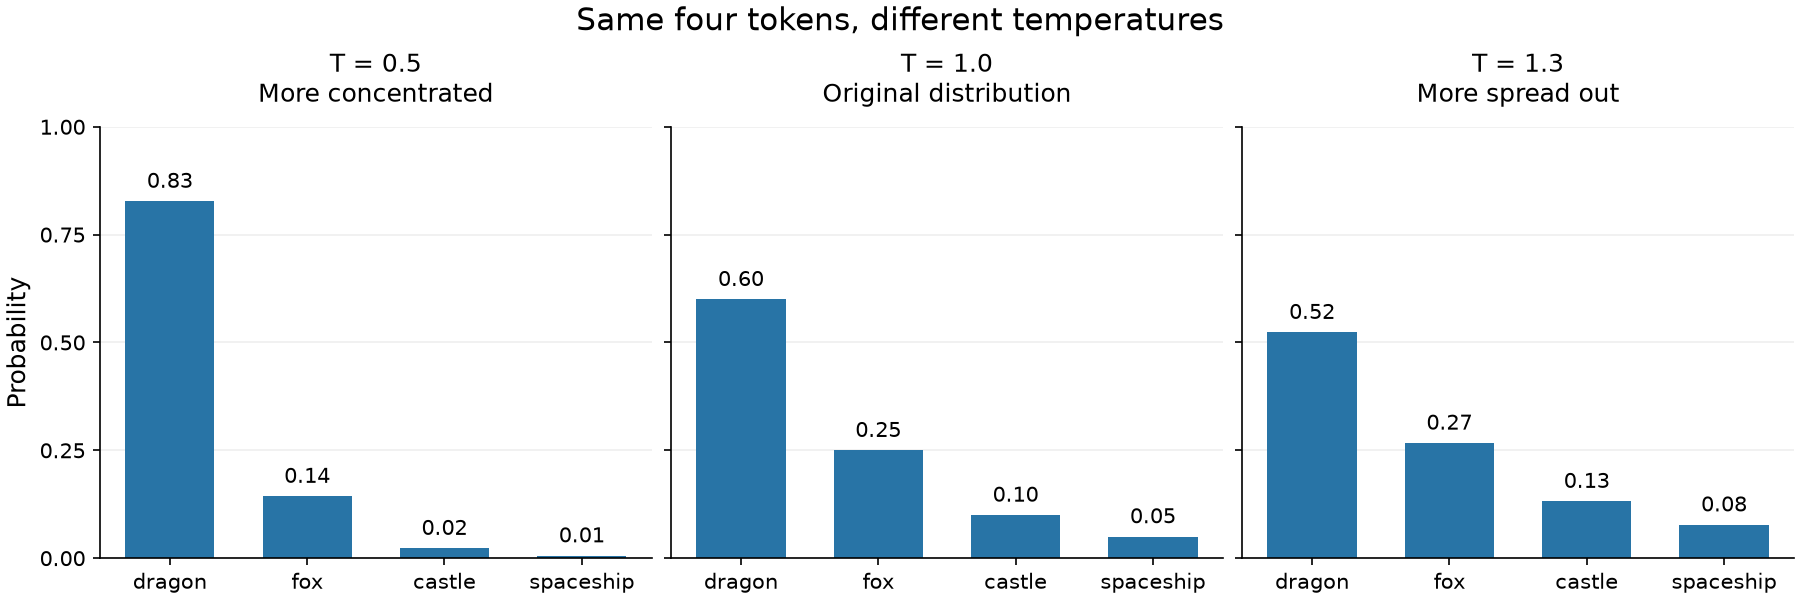

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True, constrained_layout=True)
token_names = [token.strip() for token in toy_tokens]

for ax, temperature in zip(axes, TEMPERATURES):
    probabilities = toy_distributions[temperature].tolist()
    bars = ax.bar(token_names, probabilities, color="#2874A6", width=0.65)
    ax.bar_label(bars, fmt="%.2f", padding=4, fontsize=10)
    description = ("More concentrated" if temperature < 1 else
                   "Original distribution" if temperature == 1 else "More spread out")
    ax.set_title(f"T = {temperature}\n{description}", fontsize=12, pad=12)
    ax.set_ylim(0, 1)
    ax.set_yticks([0, 0.25, 0.50, 0.75, 1])
    ax.tick_params(axis="x", labelsize=10)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Probability", fontsize=12)
fig.suptitle("Same four tokens, different temperatures", fontsize=15)
plt.show()

As temperature increases from left to right, the tallest bar falls from about 0.83 to 0.60 to 0.52, while the other bars grow. The distribution becomes less concentrated, but the most likely token stays the same. The probabilities still add to one in every panel.

**Try the draw itself.** `torch.multinomial` samples an index from the supplied probabilities. The next cell makes eight independent choices at each temperature. Every choice starts from the same four-token example; we are not building a sentence or changing the context yet.

We set a **random seed** to make the random choices reproducible in the same environment. A seed controls the random draws; it does not change the model's weights. Eight draws illustrate the process, but are too few to estimate the probabilities reliably.

In [7]:
for temperature in TEMPERATURES:
    set_seed(425)
    draws = torch.multinomial(
        toy_distributions[temperature], num_samples=8, replacement=True
    )
    choices = [toy_tokens[index].strip() for index in draws.tolist()]
    print(f"T = {temperature}: " + ", ".join(choices))

T = 0.5: dragon, dragon, dragon, dragon, dragon, dragon, dragon, dragon
T = 1.0: dragon, fox, dragon, dragon, fox, dragon, dragon, dragon
T = 1.3: dragon, fox, dragon, dragon, fox, dragon, fox, dragon


`replacement=True` allows the same token to be chosen again on later draws. Compare the choices with the probability table, while keeping in mind that a short random sample need not match those proportions.

For actual text generation, we make one draw, append the selected token, and calculate a new distribution from the longer context. Temperature is applied again at each step. We will use `generate()` to carry out this loop next.

## 4 · Comparing generated text

We now combine Sections 1–3: repeatedly predict a distribution, choose a token, and append it to the context. We keep the original prompt and model fixed, then compare greedy decoding with sampling at three temperatures.

**Choose the generation settings.** The function below returns only the new continuation. We generate up to 24 new tokens so the examples remain short; a result may end mid-sentence when it reaches that limit.

| Setting | Meaning in this experiment |
|---|---|
| `do_sample=False`, `num_beams=1` | Choose the most likely next token. |
| `do_sample=True` | Sample the next token. |
| `temperature=...` | Reshape the sampling probabilities. |
| `top_k=0`, `top_p=1.0` | Keep the full vocabulary eligible for sampling. We explain these filters in Section 5. |
| `seed=...` | Choose a reproducible sequence of random draws. |

We set both filters explicitly so that this experiment isolates temperature. Temperature is passed only when sampling is enabled. `model.eval()` remains active, keeping dropout disabled. Variation here comes from token sampling.

In [8]:
def generate_continuation(prompt, *, do_sample, temperature=1.0,
                          seed=425, top_k=0, top_p=1.0):
    set_seed(seed)
    encoded = tokenizer(prompt, return_tensors="pt").to(device)
    settings = dict(
        max_new_tokens=24,
        do_sample=do_sample,
        num_beams=1,
        pad_token_id=tokenizer.pad_token_id,
        eos_token_id=tokenizer.eos_token_id,
    )
    if do_sample:
        settings.update(temperature=temperature, top_k=top_k, top_p=top_p)
    with torch.no_grad():
        output = model.generate(**encoded, **settings)
    new_ids = output[0, encoded.input_ids.shape[1]:]
    return tokenizer.decode(new_ids, skip_special_tokens=True)

We use two seeds at each temperature to see more than one possible result. The seeds are reused across temperatures to make the comparison easier to reproduce, but they do not guarantee that the same tokens will be chosen from different distributions. Exact outputs can also differ across devices or library versions.

Read each continuation together with the prompt printed above it. Look for repeated phrases, unexpected word choices, and whether the passage stays coherent.

In [9]:
print("Prompt:", PROMPT)
greedy_text = generate_continuation(PROMPT, do_sample=False)
print("\n" + "-" * 72)
print("Greedy continuation:")
print(greedy_text)

sampled_results = []
for temperature in TEMPERATURES:
    for seed in [425, 426]:
        continuation = generate_continuation(
            PROMPT, do_sample=True, temperature=temperature, seed=seed
        )
        sampled_results.append(dict(temperature=temperature, seed=seed, text=continuation))
        print("\n" + "-" * 72)
        print(f"Sampled continuation | T = {temperature} | seed = {seed}")
        print(continuation)

Prompt: The old library was quiet. Emma opened a dusty book and found

------------------------------------------------------------------------
Greedy continuation:
 a book. She looked at the book and saw a man in the middle of the room. He looked at her and

------------------------------------------------------------------------
Sampled continuation | T = 0.5 | seed = 425
 a few books that she had never read before.


"I have a great old library, but I'm

------------------------------------------------------------------------
Sampled continuation | T = 0.5 | seed = 426
 a book in the corner. She had never heard of it before.



"I just don't want

------------------------------------------------------------------------
Sampled continuation | T = 1.0 | seed = 425
 myself filled with the books with new photos. And I was sure I wasn't alone. Momentum definitely played a part

------------------------------------------------------------------------
Sampled continuation | T = 1.0 | seed 

**Interpret:** 

Lower temperature favors tokens that already have high probability. 

Higher temperature gives less likely tokens more opportunity to appear. This can increase variety, but it can also produce less coherent text.

This small model may repeat phrases or produce awkward continuations. Changing the decoding settings does not supply missing knowledge or guarantee correctness.

**Discuss:**
1. Which continuations repeat themselves? Which are easier to follow?
2. Did the same temperature produce different text with different seeds?

**Try another prompt:** Change `YOUR_PROMPT` below and rerun the cell. Keep the seed fixed, try temperatures 0.5 and 1.3, and compare the results. Then change only the seed. Change one setting at a time so you can interpret the effect.

In [10]:
YOUR_PROMPT = "On a rainy afternoon, I found a"
YOUR_TEMPERATURE = 1.0
YOUR_SEED = 425

your_continuation = generate_continuation(
    YOUR_PROMPT, do_sample=True,
    temperature=YOUR_TEMPERATURE, seed=YOUR_SEED
)

print(f"Sampling settings | T = {YOUR_TEMPERATURE} | seed = {YOUR_SEED}")
print("-" * 72)
print("PROMPT")
print(YOUR_PROMPT)
print("-" * 72)
print("GENERATED CONTINUATION")
print(your_continuation)
print("-" * 72)

Sampling settings | T = 1.0 | seed = 425
------------------------------------------------------------------------
PROMPT
On a rainy afternoon, I found a
------------------------------------------------------------------------
GENERATED CONTINUATION
 huge mountain in the sky with no way to stay.

Who doesn't need the mountains out of the blue,
------------------------------------------------------------------------


## 5 · Top-k and top-p sampling

Temperature changes probabilities, but by itself it does not deliberately exclude the least likely tokens. **Top-k** and **top-p** restrict which tokens can be sampled. After filtering, the retained probabilities are divided by their sum so they add to one again.

Return to the original four-token example at $T=1$:

| Token | Original probability | Cumulative probability, from most to least likely |
|---|---:|---:|
| `' dragon'` | 0.60 | 0.60 |
| `' fox'` | 0.25 | 0.85 |
| `' castle'` | 0.10 | 0.95 |
| `' spaceship'` | 0.05 | 1.00 |

**Top-k with $k=2$** keeps the two most likely tokens: `' dragon'` and `' fox'`.

**Top-p with $p=0.90$** keeps the smallest leading set whose cumulative probability is at least 0.90. The first two tokens total only 0.85, so we also keep `' castle'`, reaching 0.95. We keep the token that crosses the threshold.

Next we show the probabilities after each filter. We apply these two filters separately so we can compare them.

In [11]:
K = 2
P = 0.90

top_k_probs = base_probs.clone()
top_k_probs[K:] = 0
top_k_probs = top_k_probs / top_k_probs.sum()

# Keep a token if the cumulative mass BEFORE that token is still below P.
cumulative_before = base_probs.cumsum(dim=0) - base_probs
top_p_probs = base_probs * (cumulative_before < P)
top_p_probs = top_p_probs / top_p_probs.sum()

print(f"{'Token':<16} {'Original':>10} {'Top-k = 2':>12} {'Top-p = 0.90':>14}")
for token, original, k_prob, p_prob in zip(toy_tokens, base_probs, top_k_probs, top_p_probs):
    print(f"{token!r:<16} {original:10.4f} {k_prob:12.4f} {p_prob:14.4f}")
print(f"{'Total':<16} {base_probs.sum():10.4f} {top_k_probs.sum():12.4f} {top_p_probs.sum():14.4f}")

Token              Original    Top-k = 2   Top-p = 0.90
' dragon'            0.6000       0.7059         0.6316
' fox'               0.2500       0.2941         0.2632
' castle'            0.1000       0.0000         0.1053
' spaceship'         0.0500       0.0000         0.0000
Total                1.0000       1.0000         1.0000


After top-k filtering, the probability of `' dragon'` is $0.60/(0.60+0.25)\approx0.7059$. After top-p filtering, it is $0.60/(0.60+0.25+0.10)\approx0.6316$. A displayed zero means that token cannot be selected from the filtered distribution at this step.

Top-k specifies a fixed number of candidates; top-p lets the number depend on how concentrated the probabilities are. The eligible tokens are determined again at every generation step.

**Apply each filter to the model.** The real vocabulary is much larger than four tokens, so we use `top_k=50` or `top_p=0.90`. Both runs use temperature 1 and seed 425. Compare them with the unfiltered sample with the same settings in Section 4. Using the same seed does not force the resulting texts to match.

In [12]:
filtered_results = []
print("Sampling settings | T = 1.0 | seed = 425")
print("-" * 72)
print("PROMPT")
print(PROMPT)
for label, top_k, top_p in [("Top-k = 50", 50, 1.0), ("Top-p = 0.90", 0, 0.90)]:
    continuation = generate_continuation(
        PROMPT, do_sample=True, temperature=1.0, seed=425,
        top_k=top_k, top_p=top_p
    )
    filtered_results.append(dict(method=label, text=continuation))
    print("-" * 72)
    print(f"GENERATED CONTINUATION | {label}")
    print(continuation)
print("-" * 72)

Sampling settings | T = 1.0 | seed = 425
------------------------------------------------------------------------
PROMPT
The old library was quiet. Emma opened a dusty book and found
------------------------------------------------------------------------
GENERATED CONTINUATION | Top-k = 50
 myself looking around the room with a smile.
"Goodbye Anna". A short pause.
"So, who
------------------------------------------------------------------------
GENERATED CONTINUATION | Top-p = 0.90
 myself filled with the books with new photos. And I was sure I wasn't alone. As a young girl, I
------------------------------------------------------------------------


## Recap

We followed text generation through one repeated cycle:

**Context → next-token probabilities → chosen token → longer context → next prediction**

| Choice | What changes? |
|---|---|
| Fine-tuning, as in Week 2 | The model's weights. |
| A different prompt or a previously generated token | The context used for the next prediction. |
| Greedy decoding | We select the highest-probability token at each step. |
| Sampling and temperature | We draw a token from a distribution whose concentration we can adjust. |
| Top-k or top-p filtering | We restrict which tokens can be sampled. |

In Weeks 1 and 2, loss and perplexity scored given target tokens using the model's probabilities. Today, we used those probabilities to choose new tokens. **Changing decoding settings does not train the model.**

### Check your understanding

1. Does lowering the temperature change the model's weights? What does it change?
2. In the four-token example, does the probability of `' dragon'` rise or fall when $T$ changes from 1 to 0.5?
3. Why can greedy decoding miss the most likely two-token continuation?
4. In the four-token example, how many tokens does top-p with $p=0.90$ keep, and why?
5. If two runs use the same seed but different temperatures, must they produce the same text?

<details><summary>Answers · open after discussing</summary>

1. No. Temperature reshapes the sampling probabilities at each step; the weights stay fixed.
2. It rises, from 0.60 to about 0.83, because $T<1$ concentrates probability on tokens that are already likely.
3. It chooses the most likely token at each step without looking ahead. A less likely first token followed by a very likely second token can give a higher-probability path.
4. Three. The first two tokens total 0.85, which is below 0.90, so top-p also keeps `' castle'`, reaching 0.95.
5. No. The seed fixes the random draws, but different temperatures give different distributions, so the chosen tokens can differ.

</details>


## References and further reading

- [Hugging Face: generation strategies](https://huggingface.co/docs/transformers/v4.57.1/en/generation_strategies): greedy decoding, sampling, and other decoding methods.
- [Hugging Face: generation settings](https://huggingface.co/docs/transformers/v4.57.1/en/main_classes/text_generation): `generate()` arguments such as `temperature`, `top_k`, and `top_p`.
- [DistilGPT2 model card](https://huggingface.co/distilbert/distilgpt2): the pretrained model used in Weeks 1–3.
